In [3]:
!pip install pandas numpy matplotlib seaborn openpyxl scikit-learn

Defaulting to user installation because normal site-packages is not writeable


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("Online Retail.csv")

print("Dataset loaded successfully!")
print("Original shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Original shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [5]:
# Create a copy
clean_df = df.copy()

# Remove duplicates
clean_df = clean_df.drop_duplicates()

# Remove records missing essential product/date information
clean_df = clean_df.dropna(
    subset=['StockCode', 'InvoiceDate']
)

# Remove cancelled invoices
clean_df = clean_df[
    ~clean_df['InvoiceNo'].astype(str).str.startswith('C')
]

# Remove returns and invalid sales
clean_df = clean_df[
    (clean_df['Quantity'] > 0) &
    (clean_df['UnitPrice'] > 0)
].copy()

# Convert date
clean_df['InvoiceDate'] = pd.to_datetime(
    clean_df['InvoiceDate']
)

# Calculate revenue
clean_df['Revenue'] = (
    clean_df['Quantity'] * clean_df['UnitPrice']
)

print("Data cleaning completed!")
print("Cleaned dataset shape:", clean_df.shape)

display(clean_df.head())

Data cleaning completed!
Cleaned dataset shape: (524878, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [6]:
# Missing values
print("Missing Values:")
print(clean_df.isnull().sum())

# Total revenue
total_revenue = clean_df['Revenue'].sum()

# Total units sold
total_units = clean_df['Quantity'].sum()

# Unique products
total_products = clean_df['StockCode'].nunique()

# Unique customers
total_customers = clean_df['CustomerID'].nunique()

print("\nBUSINESS SUMMARY")
print("-------------------------")
print("Total Revenue:", round(total_revenue, 2))
print("Total Units Sold:", total_units)
print("Unique Products:", total_products)
print("Unique Customers:", total_customers)

Missing Values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
dtype: int64

BUSINESS SUMMARY
-------------------------
Total Revenue: 10642110.8
Total Units Sold: 5572420
Unique Products: 3922
Unique Customers: 4338


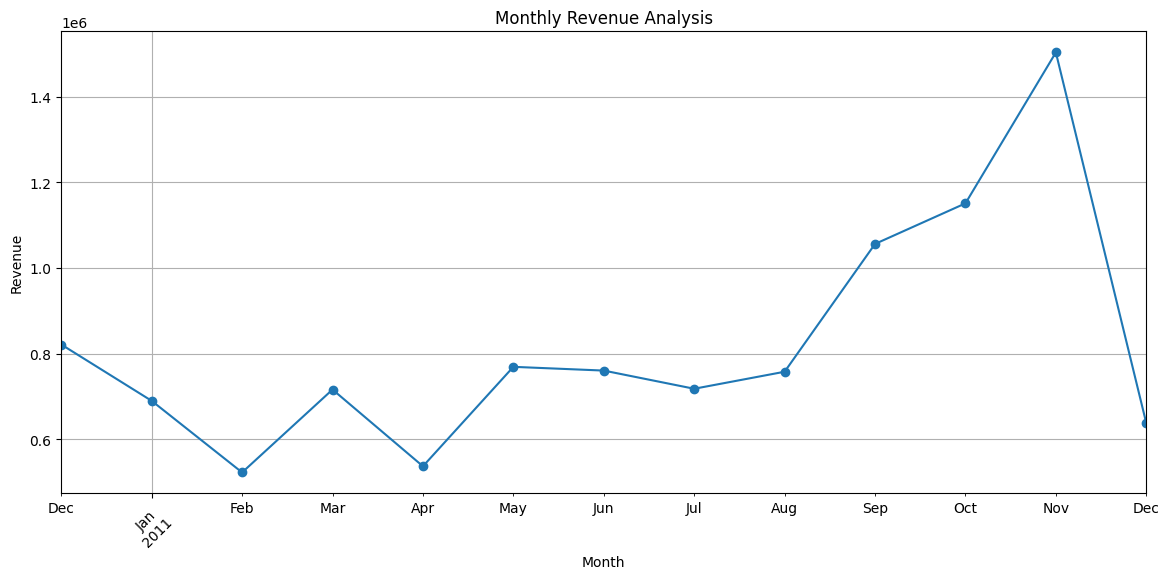

In [7]:
clean_df['Month'] = clean_df['InvoiceDate'].dt.to_period('M')

monthly_revenue = clean_df.groupby('Month')['Revenue'].sum()

plt.figure(figsize=(14, 6))

monthly_revenue.plot(marker='o')

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [8]:
selected_product = (
    clean_df.groupby('StockCode')
    .size()
    .sort_values(ascending=False)
    .index[0]
)

product_data = clean_df[
    clean_df['StockCode'] == selected_product
].copy()

print("Selected Product:", selected_product)
print("Product Description:", product_data['Description'].iloc[0])
print("Number of Transactions:", len(product_data))

Selected Product: 85123A
Product Description: WHITE HANGING HEART T-LIGHT HOLDER
Number of Transactions: 2253


Daily demand records: 374


InvoiceDate
2010-12-01    454
2010-12-02    309
2010-12-03     25
2010-12-04      0
2010-12-05    198
2010-12-06    161
2010-12-07    331
2010-12-08    151
2010-12-09    195
2010-12-10    165
Freq: D, Name: Quantity, dtype: int64

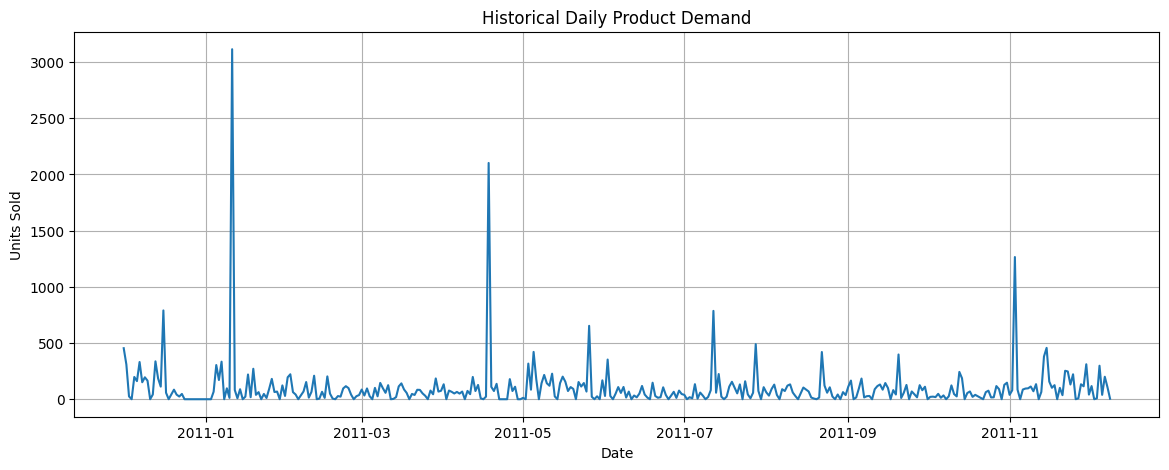

In [9]:
daily_sales = (
    product_data
    .groupby(product_data['InvoiceDate'].dt.normalize())['Quantity']
    .sum()
    .sort_index()
)

# Fill missing dates with zero demand
daily_sales = daily_sales.asfreq('D', fill_value=0)

print("Daily demand records:", len(daily_sales))

display(daily_sales.head(10))

plt.figure(figsize=(14, 5))

plt.plot(daily_sales)

plt.title("Historical Daily Product Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.grid(True)

plt.show()

In [10]:
data = pd.DataFrame({
    'Demand': daily_sales
})

# Previous demand
data['Lag_1'] = data['Demand'].shift(1)
data['Lag_7'] = data['Demand'].shift(7)
data['Lag_14'] = data['Demand'].shift(14)
data['Lag_30'] = data['Demand'].shift(30)

# Rolling averages using previous observations only
data['Rolling_Mean_7'] = (
    data['Demand'].shift(1).rolling(7).mean()
)

data['Rolling_Mean_30'] = (
    data['Demand'].shift(1).rolling(30).mean()
)

# Calendar features
data['DayOfWeek'] = data.index.dayofweek
data['Month'] = data.index.month
data['DayOfMonth'] = data.index.day

# Remove missing feature rows
data = data.dropna()

print("Feature engineering completed!")

display(data.head())

Feature engineering completed!


,Demand,Lag_1,Lag_7,Lag_14,Lag_30,Rolling_Mean_7,Rolling_Mean_30,DayOfWeek,Month,DayOfMonth
InvoiceDate,,,,,,,,,,
2010-12-31,0,0.0,0.0,58.0,454.0,0.0,125.066667,4,12,31
2011-01-01,0,0.0,0.0,0.0,309.0,0.0,109.933333,5,1,1
2011-01-02,0,0.0,0.0,42.0,25.0,0.0,99.633333,6,1,2
2011-01-03,0,0.0,0.0,85.0,0.0,0.0,98.800000,0,1,3
2011-01-04,67,0.0,0.0,41.0,198.0,0.0,98.800000,1,1,4


In [11]:
features = [
    'Lag_1',
    'Lag_7',
    'Lag_14',
    'Lag_30',
    'Rolling_Mean_7',
    'Rolling_Mean_30',
    'DayOfWeek',
    'Month',
    'DayOfMonth'
]

X = data[features]
y = data['Demand']

split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 275
Testing records: 69


In [12]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [13]:
predictions = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

# Weighted Absolute Percentage Error
wape = (
    np.abs(y_test.values - predictions).sum()
    / y_test.sum() * 100
    if y_test.sum() != 0 else np.nan
)

print("MODEL PERFORMANCE")
print("----------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("WAPE:", round(wape, 2), "%")

MODEL PERFORMANCE
----------------------------
MAE: 92.86
RMSE: 168.47
WAPE: 86.49 %


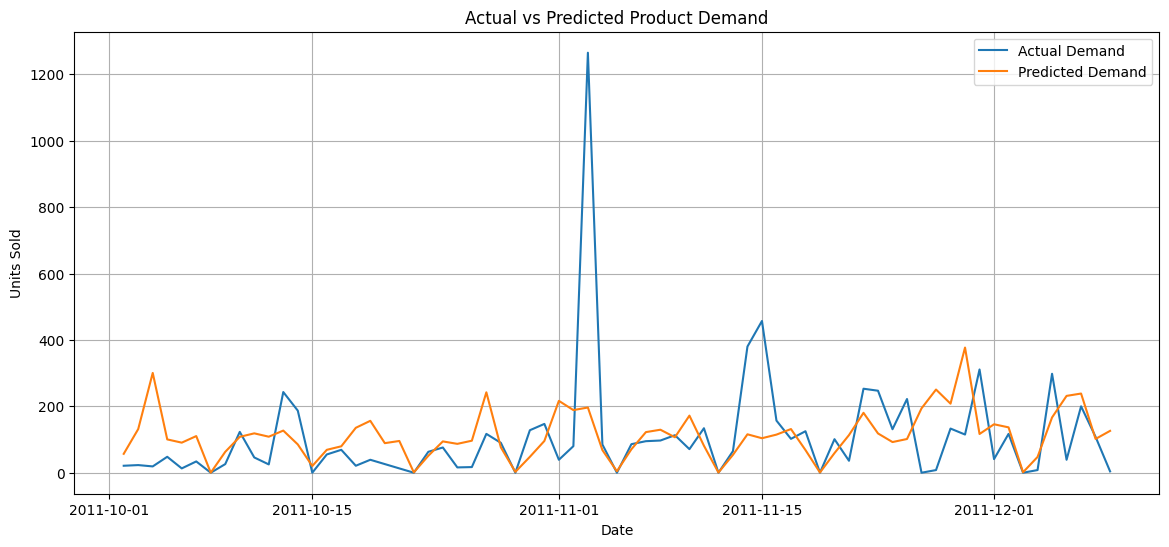

In [14]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label='Actual Demand'
)

plt.plot(
    y_test.index,
    predictions,
    label='Predicted Demand'
)

plt.title("Actual vs Predicted Product Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()
plt.grid(True)

plt.show()

In [15]:
def forecast_demand(history, model, days):

    history = history.copy().astype(float)

    future_predictions = []

    for _ in range(days):

        next_date = history.index[-1] + pd.Timedelta(days=1)

        features_row = pd.DataFrame([{
            'Lag_1': history.iloc[-1],
            'Lag_7': history.iloc[-7],
            'Lag_14': history.iloc[-14],
            'Lag_30': history.iloc[-30],
            'Rolling_Mean_7': history.iloc[-7:].mean(),
            'Rolling_Mean_30': history.iloc[-30:].mean(),
            'DayOfWeek': next_date.dayofweek,
            'Month': next_date.month,
            'DayOfMonth': next_date.day
        }])

        prediction = model.predict(
            features_row[features]
        )[0]

        prediction = max(0, prediction)

        future_predictions.append(prediction)

        history.loc[next_date] = prediction

    forecast_dates = pd.date_range(
        start=history.index[-days],
        periods=days,
        freq='D'
    )

    return pd.Series(
        future_predictions,
        index=forecast_dates,
        name='Predicted Demand'
    )


# Generate forecasts
forecast_7 = forecast_demand(daily_sales, model, 7)
forecast_30 = forecast_demand(daily_sales, model, 30)
forecast_90 = forecast_demand(daily_sales, model, 90)

print("7-Day Forecast:", round(forecast_7.sum(), 2))
print("30-Day Forecast:", round(forecast_30.sum(), 2))
print("90-Day Forecast:", round(forecast_90.sum(), 2))

display(forecast_30.to_frame())

7-Day Forecast: 601.77
30-Day Forecast: 2953.54
90-Day Forecast: 7819.14


,Predicted Demand
2011-12-10,0.000000
2011-12-11,47.728960
2011-12-12,112.921149
2011-12-13,116.287858
2011-12-14,181.133050
2011-12-15,102.777916
2011-12-16,40.916579
2011-12-17,0.000000
2011-12-18,58.772308
2011-12-19,182.945631


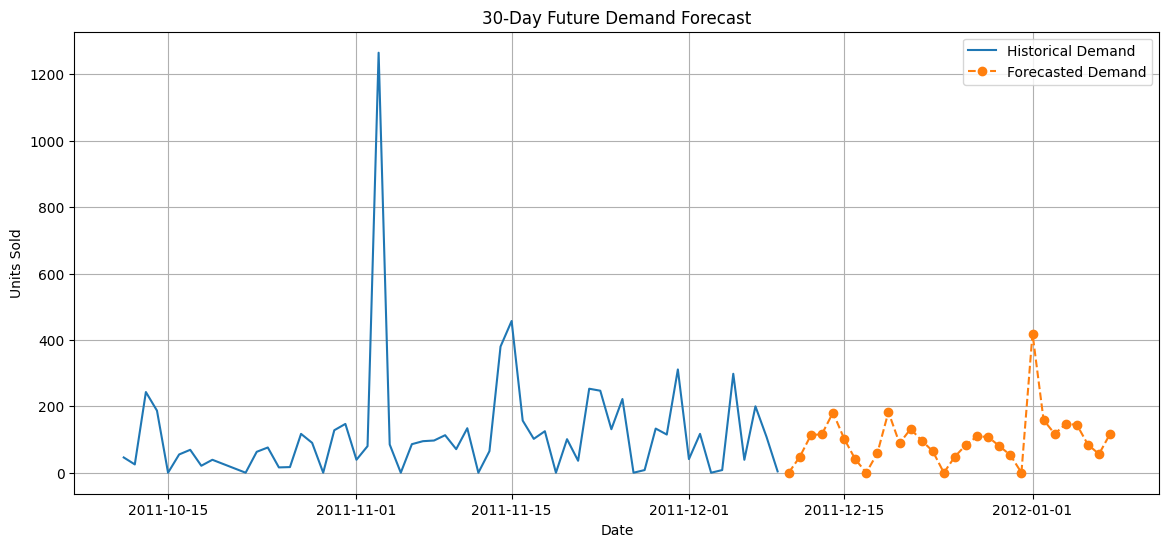

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales.index[-60:],
    daily_sales.values[-60:],
    label='Historical Demand'
)

plt.plot(
    forecast_30.index,
    forecast_30.values,
    label='Forecasted Demand',
    linestyle='--',
    marker='o'
)

plt.title("30-Day Future Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()
plt.grid(True)

plt.show()

In [17]:
# Business assumptions
lead_time = 7
service_level_z = 1.645

# Historical demand statistics
average_daily_demand = daily_sales.mean()
daily_demand_std = daily_sales.std()

# Safety stock
safety_stock = (
    service_level_z *
    daily_demand_std *
    np.sqrt(lead_time)
)

# Reorder point
reorder_point = (
    average_daily_demand * lead_time +
    safety_stock
)

# Expected demand during lead time
expected_lead_time_demand = forecast_7.sum()

# Recommended target inventory
recommended_inventory = (
    expected_lead_time_demand + safety_stock
)

print("INVENTORY PLANNING REPORT")
print("--------------------------------")

print("Average Daily Demand:",
      round(average_daily_demand, 2))

print("Expected Lead-Time Demand:",
      round(expected_lead_time_demand, 2))

print("Safety Stock:",
      round(safety_stock, 2))

print("Reorder Point:",
      round(reorder_point, 2))

print("Recommended Target Inventory:",
      round(recommended_inventory, 2))

INVENTORY PLANNING REPORT
--------------------------------
Average Daily Demand: 100.64
Expected Lead-Time Demand: 601.77
Safety Stock: 973.77
Reorder Point: 1678.28
Recommended Target Inventory: 1575.53


,Feature,Importance
5,Rolling_Mean_30,0.296596
0,Lag_1,0.173807
2,Lag_14,0.146767
4,Rolling_Mean_7,0.139309
6,DayOfWeek,0.078071
1,Lag_7,0.063372
8,DayOfMonth,0.039066
7,Month,0.036042
3,Lag_30,0.026969


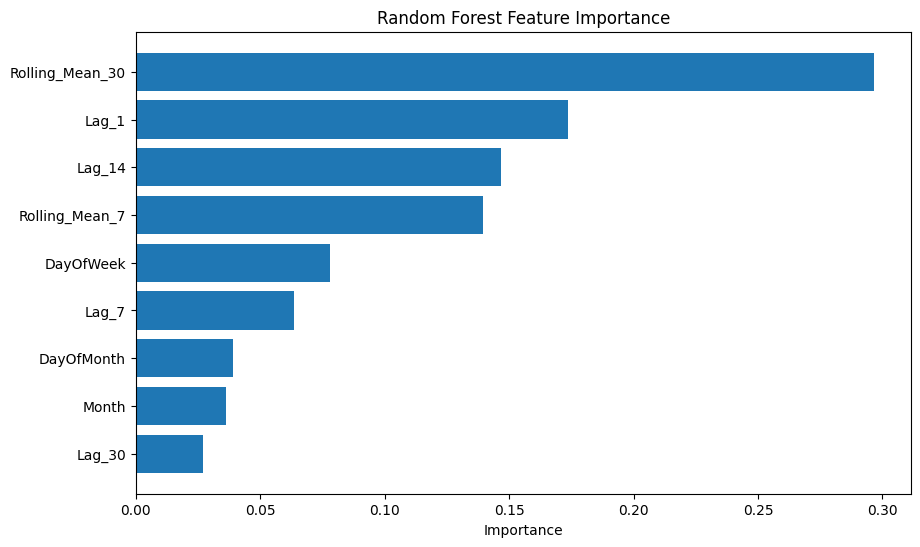

In [18]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

display(importance)

plt.figure(figsize=(10, 6))

plt.barh(
    importance['Feature'],
    importance['Importance']
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")

plt.show()

In [19]:
os.makedirs("../outputs", exist_ok=True)

# Save forecast
forecast_output = forecast_90.to_frame()

forecast_output.to_csv(
    "../outputs/future_demand_forecast.csv"
)

# Save evaluation
evaluation = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'WAPE'],
    'Value': [mae, rmse, wape]
})

evaluation.to_csv(
    "../outputs/model_evaluation.csv",
    index=False
)

# Save inventory report
inventory_report = pd.DataFrame({
    'Metric': [
        'Average Daily Demand',
        'Expected Lead-Time Demand',
        'Safety Stock',
        'Reorder Point',
        'Recommended Target Inventory'
    ],
    'Value': [
        average_daily_demand,
        expected_lead_time_demand,
        safety_stock,
        reorder_point,
        recommended_inventory
    ]
})

inventory_report.to_csv(
    "../outputs/inventory_planning_report.csv",
    index=False
)

print("All project outputs saved successfully!")

All project outputs saved successfully!
